# 04 · Modelling: boosting, imbalance handling, tuning, calibration

**Questions this notebook answers**

1. Does gradient boosting (LightGBM / XGBoost) rank fraud better than the logistic baseline?
2. Which way of handling the 1:58 class imbalance works best on the same model —
   nothing, class weights, undersampling, or SMOTE?
3. Does a small tuning budget help?
4. How much does `is_ai_generated_scam_attempt` contribute?
5. Are the predicted probabilities trustworthy, or do they need calibration?

**Protocol** (`notes/00_preregistration.md`, A2). Every comparison is paired on the same 15 folds
with the corrected resampled t-test, and **the simpler option is kept unless the more complex one
is better with a 95% CI entirely on the right side of 0**. Order of simplicity:
logistic < LightGBM < XGBoost; none < class weight < undersampling < SMOTE.
Holdout rows are never used here.

In [1]:
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e.cv import (
    load_result,
    metric_ci,
    pick,
    run_cv,
    save_result,
    verdict_text,
)
from fraud_e2e.data import load_raw
from fraud_e2e.diagnostics import smote_synthetic_vs_real
from fraud_e2e.models import DEFAULTS, normalise_spec, spec_id
from fraud_e2e.reporting import write_csv, write_json
from fraud_e2e.splits import dev_only

P.set_style()
dev = dev_only(load_raw())
decisions = []  # every pre-registered comparison, in order


def decide(simpler, complex_, step, metric="pr_auc", lower_is_better=False):
    chosen, test = pick(simpler, complex_, metric, lower_is_better)
    decisions.append({"step": step, **test})
    display(
        Markdown(
            f"**{step}** — `{complex_.name}` − `{simpler.name}` {metric}: "
            f"{test['mean_diff_b_minus_a']:+.4f} (95% CI {test['ci_low']:+.4f} to {test['ci_high']:+.4f}; "
            f"`{complex_.name}` ahead in {test['b_wins_per_folds']}/{test['n_folds']} folds) → "
            f"{verdict_text(test)}; keep **`{chosen.name}`**."
        )
    )
    return chosen


def summary_table(results):
    rows = []
    for r in results:
        row = {"pipeline": r.name}
        for m in ["pr_auc", "roc_auc", "brier"]:
            ci = metric_ci(r, m)
            row[f"{m}_mean"], row[f"{m}_ci_low"], row[f"{m}_ci_high"], row[f"{m}_sd"] = (
                ci["mean"],
                ci["ci_low"],
                ci["ci_high"],
                ci["sd"],
            )
        row["fit_seconds_15_folds"] = round(r.seconds, 1)
        rows.append(row)
    return pd.DataFrame(rows)


baseline = load_result("logreg")
print(f"dev: {len(dev):,} rows; baseline loaded: {baseline.name}")

dev: 16,000 rows; baseline loaded: logreg


## 1. LightGBM vs XGBoost (both unweighted, default settings)

In [2]:
lgbm = run_cv(dev, {"model": "lgbm"}, "lgbm")
xgb = run_cv(dev, {"model": "xgb"}, "xgb")
for r in (lgbm, xgb):
    save_result(r)
boost = decide(lgbm, xgb, "1. boosting library")

**1. boosting library** — `xgb` − `lgbm` pr_auc: -0.0039 (95% CI -0.0346 to +0.0268; `xgb` ahead in 8/15 folds) → not distinguishable; keep **`lgbm`**.

## 2. Imbalance handling on the boosting model

Same model and settings, only the imbalance strategy changes. Resampling happens inside the
training part of each fold (imblearn pipeline), never on validation rows. Candidates are tried in
order of simplicity; each replaces the current choice only if it beats it under the rule.

In [3]:
bname = boost.spec["model"]
imb = {"none": boost}
for strategy in ["class_weight", "undersample", "smote"]:
    imb[strategy] = run_cv(dev, {"model": bname, "imbalance": strategy}, f"{bname}_{strategy}")
    save_result(imb[strategy])

current = imb["none"]
for strategy in ["class_weight", "undersample", "smote"]:
    current = decide(current, imb[strategy], f"2. imbalance: {strategy}")
imb_best = current

**2. imbalance: class_weight** — `lgbm_class_weight` − `lgbm` pr_auc: -0.0225 (95% CI -0.0583 to +0.0132; `lgbm_class_weight` ahead in 2/15 folds) → not distinguishable; keep **`lgbm`**.

**2. imbalance: undersample** — `lgbm_undersample` − `lgbm` pr_auc: -0.0048 (95% CI -0.0361 to +0.0265; `lgbm_undersample` ahead in 5/15 folds) → not distinguishable; keep **`lgbm`**.

**2. imbalance: smote** — `lgbm_smote` − `lgbm` pr_auc: -0.1774 (95% CI -0.2294 to -0.1253; `lgbm_smote` ahead in 0/15 folds) → `lgbm` is better; keep **`lgbm`**.

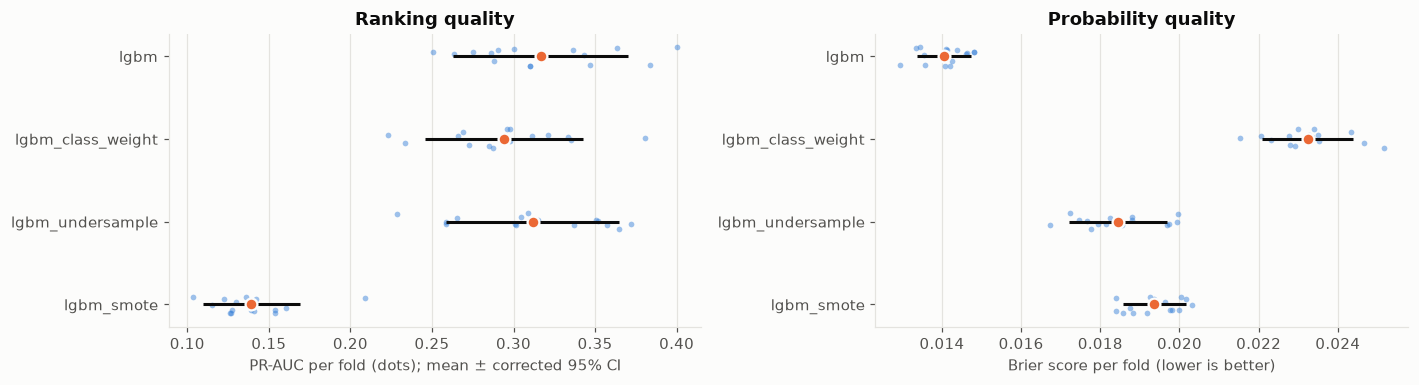

In [4]:
fig, axes = P.plt.subplots(1, 2, figsize=(13, 3.6))
P.fold_dots(
    list(imb.values()),
    "pr_auc",
    ax=axes[0],
    xlabel="PR-AUC per fold (dots); mean ± corrected 95% CI",
)
P.fold_dots(
    list(imb.values()), "brier", ax=axes[1], xlabel="Brier score per fold (lower is better)"
)
axes[0].set_title("Ranking quality")
axes[1].set_title("Probability quality")
fig.tight_layout()
P.save(fig, "p2_imbalance_folds")
P.plt.show()

Resampling and weighting tell the model fraud is far more common than it is, so its raw
probabilities are inflated (higher Brier). That is fixable by calibration; ranking (PR-AUC) is
what the comparison above decides on.

**Why SMOTE hurts here — a diagnostic.** SMOTENC builds synthetic fraud by interpolating numeric
features between a fraud case and its nearest fraud neighbours, and sets each categorical/boolean
feature to the most common value among those neighbours. The table compares the synthetic cases with
the real fraud they were made from (one training fold).

In [5]:
smote_diag = smote_synthetic_vs_real(dev, {"model": bname})
write_csv(smote_diag, "p2_smote_diagnostic")
smote_diag.round(3)

,feature,real_fraud_mean,synthetic_fraud_mean,legit_mean,n_real_fraud,n_synthetic
0,is_foreign_transaction,0.230,0.056,0.056,217,1041
1,is_new_merchant,0.498,0.513,0.229,217,1041
2,used_vpn,0.207,0.036,0.087,217,1041
3,ip_country_mismatch,0.313,0.180,0.054,217,1041
4,billing_shipping_mismatch,0.207,0.026,0.041,217,1041
5,is_ai_generated_scam_attempt,0.088,0.014,0.017,217,1041
6,cvv_retry_count,0.700,0.359,0.177,217,1041
7,merchant_risk_score,50.113,49.403,37.247,217,1041
8,velocity_score,28.781,27.895,19.707,217,1041


In [6]:
flags = smote_diag[smote_diag["feature"].isin(C.BOOLEAN_COLS)]
ratio = (flags["synthetic_fraud_mean"] / flags["real_fraud_mean"]).mean()
cvv = smote_diag.set_index("feature").loc["cvv_retry_count"]
display(
    Markdown(
        f"On average a red-flag feature is present in synthetic fraud only **{ratio:.2f}×** as often as "
        f"in real fraud (CVV retries: {cvv['synthetic_fraud_mean']:.2f} vs {cvv['real_fraud_mean']:.2f}). "
        "Each flag is absent in most fraud cases, so the neighbours' majority vote usually sets it "
        "to 0. The synthetic 'fraud' therefore looks "
        "much more like legitimate traffic, which teaches the model the wrong boundary."
    )
)

On average a red-flag feature is present in synthetic fraud only **0.38×** as often as in real fraud (CVV retries: 0.36 vs 0.70). Each flag is absent in most fraud cases, so the neighbours' majority vote usually sets it to 0. The synthetic 'fraud' therefore looks much more like legitimate traffic, which teaches the model the wrong boundary.

## 3. Small tuning budget

20 random configurations of the chosen boosting pipeline, scored on repeat `r0` only (5 folds).
The best one is then run on all 15 folds and compared with the untuned pipeline. Because the
configuration was picked on `r0`, the tuned CV score is optimistically biased; the holdout is
the unbiased check.

In [7]:
rng = np.random.default_rng(C.SEED)
if bname == "lgbm":
    space = {
        "num_leaves": [7, 15, 31, 63],
        "learning_rate": lambda: float(np.round(10 ** rng.uniform(-2, -1), 4)),
        "n_estimators": [200, 400, 800],
        "min_child_samples": [10, 20, 50, 100],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.5, 0.7, 0.9],
        "reg_lambda": [0.0, 0.1, 1.0, 10.0],
    }
else:
    space = {
        "max_depth": [2, 3, 4, 6],
        "learning_rate": lambda: float(np.round(10 ** rng.uniform(-2, -1), 4)),
        "n_estimators": [200, 400, 800],
        "min_child_weight": [0.1, 0.33, 1.0, 3.0],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.5, 0.7, 0.9],
        "reg_lambda": [0.1, 1.0, 10.0],
    }


def sample():
    return {k: (v() if callable(v) else v[rng.integers(len(v))]) for k, v in space.items()}


configs = [sample() for _ in range(20)]
trials = []
for i, params in enumerate(configs):
    spec = {**imb_best.spec, "params": params}
    r = run_cv(dev, spec, f"trial_{i:02d}", repeats=(0,))
    trials.append(
        {
            "trial": i,
            **params,
            "pr_auc_r0_mean": r.folds["pr_auc"].mean(),
            "pr_auc_r0_sd": r.folds["pr_auc"].std(ddof=1),
            "seconds": r.seconds,
        }
    )
trials = pd.DataFrame(trials).sort_values("pr_auc_r0_mean", ascending=False).reset_index(drop=True)
write_csv(trials, "p2_tuning_trials")
untuned_r0 = imb_best.folds.query("repeat == 0")["pr_auc"].mean()
display(Markdown(f"Untuned pipeline on `r0`: PR-AUC {untuned_r0:.4f}. Top 5 trials:"))
trials.head(5)

Untuned pipeline on `r0`: PR-AUC 0.3209. Top 5 trials:

,trial,num_leaves,learning_rate,n_estimators,min_child_samples,subsample,colsample_bytree,reg_lambda,pr_auc_r0_mean,pr_auc_r0_sd,seconds
0,5,7,0.0226,800,10,1.0,0.7,10.0,0.384089,0.067588,1.941482
1,1,7,0.0945,200,50,1.0,0.9,10.0,0.379817,0.070748,0.583515
2,12,7,0.0138,800,100,0.6,0.9,0.0,0.379014,0.075916,1.996788
3,4,7,0.0116,400,100,1.0,0.5,1.0,0.372283,0.093649,1.107653
4,17,31,0.0273,200,100,0.6,0.5,0.1,0.360190,0.084220,1.760001


In [8]:
best_params = configs[int(trials.iloc[0]["trial"])]
tuned = run_cv(dev, {**imb_best.spec, "params": best_params}, f"{imb_best.name}_tuned")
save_result(tuned)
boost_best = decide(imb_best, tuned, "3. tuning")

**3. tuning** — `lgbm_tuned` − `lgbm` pr_auc: +0.0501 (95% CI +0.0141 to +0.0862; `lgbm_tuned` ahead in 15/15 folds) → `lgbm_tuned` is better; keep **`lgbm_tuned`**.

## 4. Best boosting pipeline vs the logistic baseline

In [9]:
final_family = decide(baseline, boost_best, "4. boosting vs logistic")

**4. boosting vs logistic** — `lgbm_tuned` − `logreg` pr_auc: -0.0484 (95% CI -0.0843 to -0.0125; `lgbm_tuned` ahead in 0/15 folds) → `logreg` is better; keep **`logreg`**.

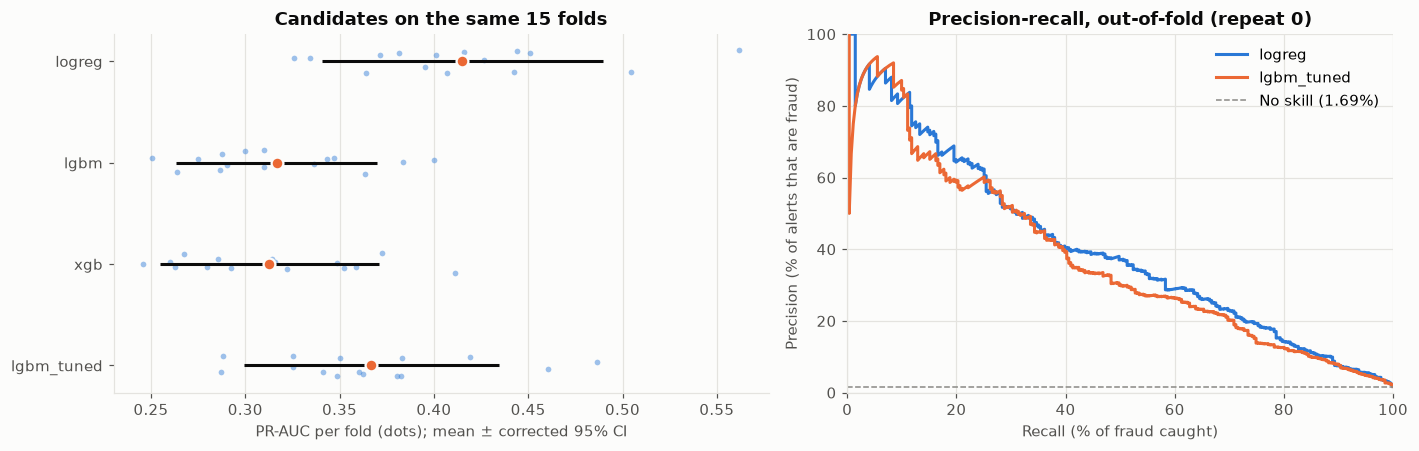

In [10]:
fig, axes = P.plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
P.fold_dots(
    list({r.name: r for r in [baseline, lgbm, xgb, imb_best, tuned]}.values()),
    "pr_auc",
    ax=axes[0],
    xlabel="PR-AUC per fold (dots); mean ± corrected 95% CI",
)
axes[0].set_title("Candidates on the same 15 folds")
P.pr_curves([baseline, boost_best], ax=axes[1])
axes[1].set_title("Precision-recall, out-of-fold (repeat 0)")
fig.tight_layout()
P.save(fig, "p2_model_comparison")
P.plt.show()

## 5. Ablation: without `is_ai_generated_scam_attempt`

Pre-registered in P1: the column behaves like an ordinary risk signal, so it stays in the model;
here we measure how much it adds. This comparison is reported, it does not change the choice.

In [11]:
abl_spec = {**final_family.spec, "drop": ["is_ai_generated_scam_attempt"]}
ablation = run_cv(dev, abl_spec, f"{final_family.name}_no_ai_flag")
save_result(ablation, with_oof=False)
_, abl_test = pick(ablation, final_family, "pr_auc")
abl_test["step"] = "5. ablation (reported only)"
abl_test.pop("chosen")
decisions.append(abl_test)
display(
    Markdown(
        f"With the flag − without: PR-AUC {abl_test['mean_diff_b_minus_a']:+.4f} "
        f"(95% CI {abl_test['ci_low']:+.4f} to {abl_test['ci_high']:+.4f}) → {verdict_text(abl_test)}."
    )
)

With the flag − without: PR-AUC +0.0283 (95% CI +0.0113 to +0.0453) → `logreg` is better.

## 6. Calibration

Each candidate wraps the final pipeline in `CalibratedClassifierCV` (inner 5-fold, inside every
outer training fold). Lower Brier score is better; the order of simplicity is none < sigmoid <
isotonic.

In [12]:
cal = {"none": final_family}
for method in ["sigmoid", "isotonic"]:
    cal[method] = run_cv(
        dev, {**final_family.spec, "calibration": method}, f"{final_family.name}_{method}"
    )
    save_result(cal[method], with_oof=False)

current = cal["none"]
for method in ["sigmoid", "isotonic"]:
    current = decide(
        current, cal[method], f"6. calibration: {method}", metric="brier", lower_is_better=True
    )
final = current

**6. calibration: sigmoid** — `logreg_sigmoid` − `logreg` brier: -0.0000 (95% CI -0.0001 to +0.0001; `logreg_sigmoid` ahead in 5/15 folds) → not distinguishable; keep **`logreg`**.

**6. calibration: isotonic** — `logreg_isotonic` − `logreg` brier: +0.0001 (95% CI -0.0001 to +0.0002; `logreg_isotonic` ahead in 11/15 folds) → not distinguishable; keep **`logreg`**.

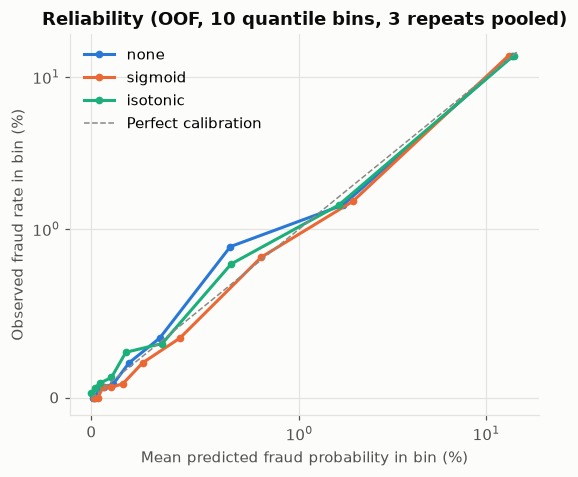

In [13]:
from sklearn.calibration import calibration_curve  # noqa: E402

fig, ax = P.plt.subplots(figsize=(5.5, 4.5))
for i, (method, r) in enumerate(cal.items()):
    o = r.oof
    prob_true, prob_pred = calibration_curve(o["y"], o["score"], n_bins=10, strategy="quantile")
    ax.plot(
        prob_pred * 100, prob_true * 100, marker="o", ms=4, lw=2, color=P.SERIES[i], label=method
    )
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], color=P.NEUTRAL, ls="--", lw=1, label="Perfect calibration")
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Mean predicted fraud probability in bin (%)")
ax.set_ylabel("Observed fraud rate in bin (%)")
ax.set_title("Reliability (OOF, 10 quantile bins, 3 repeats pooled)")
ax.legend()
P.save(fig, "p2_calibration")
P.plt.show()

## 7. Freeze the final pipeline

In [14]:
final_out = replace(final, name="final")
save_result(final_out)

all_results = [
    baseline,
    load_result("logreg_balanced"),
    lgbm,
    xgb,
    *list(imb.values())[1:],
    tuned,
    ablation,
    *list(cal.values())[1:],
]
table = summary_table(all_results)
write_csv(table, "p2_model_summary")
write_csv(pd.DataFrame(decisions), "p2_decisions")
final_spec = normalise_spec(final.spec)
write_json(
    {
        "final_pipeline": {
            "name": final.name,
            "spec": final_spec,
            "spec_id": spec_id(final_spec),
            **{m: metric_ci(final_out, m) for m in ["pr_auc", "roc_auc", "brier"]},
        },
        "defaults": DEFAULTS,
        "decisions": decisions,
        "ablation_ai_flag": abl_test,
        "tuning": {"n_trials": len(trials), "scored_on": "repeat r0", "best_params": best_params},
    },
    "p2_modeling",
)
table.round(4)

,pipeline,pr_auc_mean,pr_auc_ci_low,pr_auc_ci_high,pr_auc_sd,roc_auc_mean,roc_auc_ci_low,roc_auc_ci_high,roc_auc_sd,brier_mean,brier_ci_low,brier_ci_high,brier_sd,fit_seconds_15_folds
0,logreg,0.4151,0.3406,0.4896,0.0617,0.9425,0.9283,0.9566,0.0117,0.0125,0.0117,0.0134,0.0007,0.3
1,logreg_balanced,0.3914,0.3153,0.4675,0.0630,0.9352,0.9193,0.9511,0.0132,0.0890,0.0847,0.0933,0.0035,0.3
2,lgbm,0.3166,0.2632,0.3699,0.0442,0.9258,0.9156,0.9360,0.0084,0.0141,0.0134,0.0147,0.0006,4.5
3,xgb,0.3126,0.2545,0.3707,0.0481,0.9249,0.9149,0.9350,0.0083,0.0139,0.0132,0.0146,0.0006,2.7
4,lgbm_class_weight,0.2940,0.2456,0.3425,0.0401,0.9216,0.9100,0.9331,0.0096,0.0232,0.0221,0.0244,0.0010,4.6
5,lgbm_undersample,0.3117,0.2585,0.3649,0.0441,0.9243,0.9131,0.9355,0.0093,0.0184,0.0172,0.0197,0.0010,3.7
6,lgbm_smote,0.1392,0.1095,0.1689,0.0246,0.8579,0.8355,0.8803,0.0186,0.0194,0.0186,0.0202,0.0007,7.9
7,lgbm_tuned,0.3667,0.2992,0.4343,0.0560,0.9336,0.9205,0.9467,0.0108,0.0132,0.0126,0.0138,0.0005,5.9
8,logreg_no_ai_flag,0.3868,0.3122,0.4615,0.0619,0.9380,0.9221,0.9539,0.0132,0.0129,0.0121,0.0138,0.0007,0.3
9,logreg_sigmoid,0.4156,0.3413,0.4899,0.0615,0.9425,0.9286,0.9563,0.0115,0.0125,0.0117,0.0134,0.0007,1.3


## Summary

In [15]:
fin = metric_ci(final_out, "pr_auc")
fin_roc = metric_ci(final_out, "roc_auc")
fin_brier = metric_ci(final_out, "brier")
base_ci = metric_ci(baseline, "pr_auc")
boost_ci = metric_ci(boost_best, "pr_auc")
d4 = next(d for d in decisions if d["step"].startswith("4."))
lines = "\n".join(
    f"  - {d['step']}: {verdict_text(d)} → `{d['chosen']}`" for d in decisions if "chosen" in d
)
display(
    Markdown(f"""
- **Final pipeline: `{final.name}`** — PR-AUC **{fin["mean"]:.3f}** (95% CI {fin["ci_low"]:.3f}–{fin["ci_high"]:.3f}),
  ROC-AUC {fin_roc["mean"]:.3f} ({fin_roc["ci_low"]:.3f}–{fin_roc["ci_high"]:.3f}),
  Brier {fin_brier["mean"]:.4f}.
- **Boosting vs logistic:** best boosting pipeline `{d4["b"]}` (PR-AUC {boost_ci["mean"]:.3f}) minus
  logistic `{d4["a"]}` (PR-AUC {base_ci["mean"]:.3f}) = {d4["mean_diff_b_minus_a"]:+.4f}
  (95% CI {d4["ci_low"]:+.4f} to {d4["ci_high"]:+.4f}) → {verdict_text(d4)}. The P1 red-flag
  pattern (each flag multiplies the odds) is exactly what a logistic model represents, which is a
  plausible reason trees add nothing here.
- **SMOTE** cut PR-AUC to {metric_ci(imb["smote"], "pr_auc")["mean"]:.3f}: synthetic fraud carried
  red flags only {ratio:.2f}× as often as real fraud (diagnostic above).
- **Decisions in pre-registered order:**
{lines}
- **`is_ai_generated_scam_attempt`:** with − without = {abl_test["mean_diff_b_minus_a"]:+.4f}
  (95% CI {abl_test["ci_low"]:+.4f} to {abl_test["ci_high"]:+.4f}); {verdict_text(abl_test)}.
- The tuned score was selected on repeat `r0`, so it is optimistic; the holdout (notebook 05)
  gives the unbiased number.
""")
)


- **Final pipeline: `logreg`** — PR-AUC **0.415** (95% CI 0.341–0.490),
  ROC-AUC 0.942 (0.928–0.957),
  Brier 0.0125.
- **Boosting vs logistic:** best boosting pipeline `lgbm_tuned` (PR-AUC 0.367) minus
  logistic `logreg` (PR-AUC 0.415) = -0.0484
  (95% CI -0.0843 to -0.0125) → `logreg` is better. The P1 red-flag
  pattern (each flag multiplies the odds) is exactly what a logistic model represents, which is a
  plausible reason trees add nothing here.
- **SMOTE** cut PR-AUC to 0.139: synthetic fraud carried
  red flags only 0.38× as often as real fraud (diagnostic above).
- **Decisions in pre-registered order:**
  - 1. boosting library: not distinguishable → `lgbm`
  - 2. imbalance: class_weight: not distinguishable → `lgbm`
  - 2. imbalance: undersample: not distinguishable → `lgbm`
  - 2. imbalance: smote: `lgbm` is better → `lgbm`
  - 3. tuning: `lgbm_tuned` is better → `lgbm_tuned`
  - 4. boosting vs logistic: `logreg` is better → `logreg`
  - 6. calibration: sigmoid: not distinguishable → `logreg`
  - 6. calibration: isotonic: not distinguishable → `logreg`
- **`is_ai_generated_scam_attempt`:** with − without = +0.0283
  (95% CI +0.0113 to +0.0453); `logreg` is better.
- The tuned score was selected on repeat `r0`, so it is optimistic; the holdout (notebook 05)
  gives the unbiased number.
